# NumPy und Pandas: Verteilungen ziehen, Zeitstempel auswerten
### Unterrichtsmaterial | Julia Brutskaya

---
**Kontext:** Wahrscheinlichkeitsrechnung, Tag 4 – stetige Verteilungen und die Normalverteilung<br>
**Bibliotheken:** `numpy`, `pandas`, `matplotlib`

<img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="130"> <img src="png%20Dateien/nils_eichhoernchen.png" alt="Nils" width="130"> <img src="png%20Dateien/etta_elster.png" alt="Etta" width="130"> <img src="png%20Dateien/der_ausreisser.png" alt="Der Ausreißer" width="130">

Neulich ging es um stetige Verteilungen: Dichte, Fläche, Normalverteilung, z-Werte, Poisson, Exponential und Weibull. Nun ziehen wir alle diese Verteilungen mit NumPy und werten sie mit Pandas aus.

Zwei neue Werkzeugkästen:

- **NumPy Random:** Zufallszahlen aus jeder Verteilung des Tages. S. Kapitel „Random" im W3Schools-Tutorial.
- **Datum und Zeit in Pandas:** ein Ticket-Log mit Zeitstempeln, ausgewertet pro Stunde und pro Wochentag.

| Block | Inhalt | Neu |
|---|---|---|
| A | NumPy Random: Generator und W3Schools | `rng.choice(p=…)`, `rng.permutation`, alte und neue Schreibweise |
| B | Sechs Verteilungen in einer Tabelle | `rng.uniform`, `normal`, `poisson`, `exponential`, `weibull`; `skew()` |
| C | Histogramm, Dichte und Fläche | `hist(density=True)`, Sigma-Regeln auszählen |
| D | Ein Ticket-Log mit Zeitstempeln | `pd.to_timedelta`, `resample`, `diff`, `.dt.total_seconds()`, `.dt.hour`, `.dt.day_name()` |
| E | z-Werte pro Gruppe | `groupby().transform` |
| F | Weitere Übungen | Anfahrt, Dichte > 1, S-Bahn, Montagmorgen, Zusatz-Verteilungen |

---
# Block A – NumPy Random: Generator und W3Schools

## 1 – Zwei Schreibweisen für dasselbe

Seit der Mathe-Woche benutzt ihr den **Generator** `rng = np.random.default_rng(seed)`. Im W3Schools-Tutorial steht die **ältere** Schreibweise `from numpy import random`. Beide funktionieren. Wir bleiben beim Generator, die Tabelle hilft beim Lesen von W3Schools:

| W3Schools (alt) | Generator (Kurs) | Skript 4 |
|---|---|---|
| `random.rand(5)` | `rng.random(5)` | Gleichverteilung [0, 1) |
| `random.uniform(low, high, size)` | `rng.uniform(low, high, size)` | Abschnitt 3 - Die stetige Gleichverteilung (Uniformverteilung/ Rechteckverteilung |
| `random.normal(loc, scale, size)` | `rng.normal(loc, scale, size)` | Abschnitt 4 - Die Normalverteilung (Gauß-Verteilung) |
| `random.binomial(n, p, size)` | `rng.binomial(n, p, size)` | Skript 3, Abschnitt 6 - Die Binomialverteilung |
| `random.poisson(lam, size)` | `rng.poisson(lam, size)` | Abschnitt 6.1 - Poisson-Verteilung|
| `random.exponential(scale, size)` | `rng.exponential(scale, size)` | Abschnitt 6.2 - Exponentialverteilung, **scale = 1/λ** |
| `random.choice(liste, p=[…], size)` | `rng.choice(liste, p=[…], size)` | „Data Distribution" |
| `random.permutation(x)` | `rng.permutation(x)` | „Random Permutation" |
| – | `rng.weibull(k, size)` | Abschnitt 6.3 |

`loc` ist der Mittelwert μ, `scale` die Standardabweichung σ. W3Schools zeichnet mit `seaborn`, wir mit Matplotlib.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BLAU, ORANGE = "#2a78d6", "#eb6834"
rng = np.random.default_rng(42)

print(rng.random(5).round(3).tolist())                          # 5 Zahlen zwischen 0 und 1
print(rng.normal(loc=45, scale=5, size=3).round(1).tolist())    # Normalverteilung

[0.774, 0.439, 0.859, 0.697, 0.094]
[38.5, 45.6, 43.4]


In [2]:
# Nur zum Vergleich: so steht es bei W3Schools
from numpy import random
print(random.normal(loc=45, scale=5, size=3).round(1).tolist())

[43.8, 51.4, 44.7]


> **Achtung:** `from numpy import random` überschreibt den Namen `random`, falls vorher das Python-Modul `random` importiert wurde. Diese Schreibweise deshalb nur in dieser einen Demo-Zelle benutzen.

## 2 – Ziehen mit Wahrscheinlichkeiten und Mischen

`rng.choice(liste, p=[…])` zieht aus einer Liste mit vorgegebenen Wahrscheinlichkeiten („Data Distribution") und dasselbe wie `sample(weights=…)` aus Notebook 8, nur in NumPy.

`rng.permutation` bringt eine Liste in zufällige Reihenfolge, zum Beispiel die Reihenfolge der Präsentationen.

In [3]:
rng = np.random.default_rng(42)
getraenke = rng.choice(["Kaffee", "Tee", "Mate", "Wasser"], size=10, p=[0.4, 0.25, 0.2, 0.15])
print(getraenke.tolist())

reihenfolge = rng.permutation([101, 102, 103, 104, 105])
print("Präsentationen:", reihenfolge.tolist())

['Mate', 'Tee', 'Wasser', 'Mate', 'Kaffee', 'Wasser', 'Mate', 'Mate', 'Kaffee', 'Tee']
Präsentationen: [105, 101, 103, 104, 102]


### Übung 1

- **a)** In der Kurs-Umfrage trinken 8 von 20 Kaffee, 5 Tee, 4 Mate und 3 Wasser. Ziehe mit `rng.choice` 1000 erfundene Personen mit genau diesen Anteilen (`rng = np.random.default_rng(1)`).
- **b)** Prüfe die Anteile mit `value_counts(normalize=True)`. Wie nah bist du an 0,40 / 0,25 / 0,20 / 0,15?
- **c)** Lege mit `rng.permutation` eine zufällige Präsentations-Reihenfolge für die Teilnehmer-IDs 101 bis 120 fest.

In [ ]:
# a) P= Anteil der Umfrage 
rng = np.random.default_rng(1)
personen = pd.Series(rng.choice(["Kaffee", "Tee", "Mate", "Wasser"], size=1000, p=[8/20, 5/20, 4/20, 3/20]))
personen.head()

0       Tee
1    Wasser
2    Kaffee
3    Wasser
4    Kaffee
dtype: str

In [64]:
# b)
print(personen.value_counts(normalize=True).round(3))

Kaffee    0.415
Tee       0.235
Mate      0.196
Wasser    0.154
Name: proportion, dtype: float64


In [65]:
# c)
print(rng.permutation(range(101, 121)).tolist())

[108, 104, 103, 113, 106, 118, 109, 105, 101, 116, 119, 120, 111, 117, 115, 114, 102, 112, 110, 107]


---
# Block B – Sechs Verteilungen in einer Tabelle

## 3 – Eine Spalte pro Verteilung

Wir ziehen von jeder Verteilung des Tages 100 000 Werte, mit den Beispielen aus dem Skript.

In [7]:
rng = np.random.default_rng(42)
n = 100_000
ziehungen = pd.DataFrame({
    "gleich":      rng.uniform(0, 10, n),               # S-Bahn alle 10 Minuten, E = 5
    "normal":      rng.normal(45, 5, n),                # API-Latenz μ = 45 ms, σ = 5 ms
    "binomial":    rng.binomial(20, 0.05, n),           # 20 Server, p = 5 %, E = 1
    "poisson":     rng.poisson(4, n),                   # 4 Tickets pro Stunde, E = Varianz = 4
    "exponential": rng.exponential(scale=1/4, size=n),  # Wartezeit in Stunden, E = 1/λ = 0,25
    "weibull":     5 * rng.weibull(2, n),               # Lebensdauer: Form k = 2, Skala λ = 5 Jahre
})
ziehungen.head()

,gleich,normal,binomial,poisson,exponential,weibull
0,7.739560,50.322939,2,3,0.718615,2.176495
1,4.388784,38.471621,2,3,0.157392,5.505252
2,8.585979,47.789137,1,5,0.334462,1.403999
3,6.973680,45.047314,1,0,0.022989,3.761656
4,0.941773,56.841935,0,3,0.257747,1.808018


In [8]:
ziehungen.describe().round(2).T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
gleich,5.01,2.89,0.00,5.02,10.00
normal,45.01,5.01,20.92,45.01,69.97
binomial,1.00,0.97,0.00,1.00,7.00
poisson,4.00,2.00,0.00,4.00,16.00
exponential,0.25,0.25,0.00,0.17,2.81
weibull,4.43,2.31,0.01,4.16,18.15


Zwei Stolpersteine:

> **Exponential:** `rng.exponential(scale=…)` erwartet **1/λ**, nicht λ. Bei λ = 4 Tickets pro Stunde ist `scale=1/4` (Stunden) oder `scale=15` (Minuten). `rng.exponential(4)` hätte Wartezeiten mit Mittelwert 4 Stunden ergeben.

> **Weibull:** `rng.weibull(k)` hat immer die Skala λ = 1. Für λ = 5 Jahre mit 5 multiplizieren.

## 4 – Ist alles normalverteilt?

> **Herr Bauchgefühl:** „Alles im Leben ist normalverteilt: Körpergrößen, Noten, Antwortzeiten, Anfahrtswege. Immer diese schöne Glocke."

`skew()` misst die **Schiefe**: 0 heißt symmetrisch, positiv heißt rechtsschief (langer Schwanz nach rechts). Ausführlich kommt das morgen, heute nur als Blick.

In [68]:
ziehungen.skew().round(8)

gleich        -0.004885
normal         0.017427
binomial       0.908944
poisson        0.498686
exponential    1.989095
weibull        0.628118
dtype: float64

Nur `gleich` und `normal` sind symmetrisch. Die Exponentialverteilung ist stark rechtsschief: viele kurze Wartezeiten, wenige sehr lange.

### Übung 2

Vergleiche die Ziehungen mit dem Steckbrief aus Skript Abschnitt 6.5.

- **a)** Lege eine Tabelle mit den Spalten `formel` (Erwartungswert laut Skript) und `simuliert` (Mittelwert aus `ziehungen`) an. Für Weibull mit k = 2 gilt E ≈ 0,886 · λ.
- **b)** Bei Poisson ist Erwartungswert = Varianz. Prüfe das mit `mean()` und `var()`.
- **c)** Welche Verteilung ist am schiefsten? Passt das zum Skript?

In [71]:
# a)
formel = pd.Series({"gleich": 5, "normal": 45, "binomial":20 * 0.05, "poisson": 4, 
                    "exponential": 1/4, "weibull": 0.886 *5})
steckbrief = pd.DataFrame({"formel": formel, "simuliert": ziehungen.mean()})
steckbrief.round(3)

,formel,simuliert
gleich,5.00,5.006
normal,45.00,45.014
binomial,1.00,1.001
poisson,4.00,3.999
exponential,0.25,0.251
weibull,4.43,4.428


In [72]:
# b)Poisson: 
print("Mittelwert", round(ziehungen["poisson"].mean(), 3))
print("Varianz", round(ziehungen["poisson"].var(), 3))

Mittelwert 3.999
Varianz 3.982


In [73]:
# c)
print(ziehungen.skew().idxmax(), round(ziehungen.skew().max(), 2))

exponential 1.99


---
# Block C – Histogramm, Dichte und Fläche

## 5 – Vom Histogramm zur Dichtekurve

<img src="png%20Dateien/nils_eichhoernchen.png" alt="Nils" width="110">

**Nils:** „Bei Millisekunden müsste ich unendlich fein zählen. Also zähle ich in Bereichen."

Mit `density=True` zeigt das Histogramm keine Anzahl mehr, sondern eine **Dichte**: Die Fläche aller Balken ergibt 1. Darüber zeichnen wir die Dichtekurve der Normalverteilung mit der Formel aus Skript 4.2:
$$f(x) = \frac{1}{\sigma\sqrt{2\pi}} \cdot e^{-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^2}$$

| Code | Formel | Bedeutung |
|---|---|---|
| `(xs - 45) / 5` | $\frac{x-\mu}{\sigma}$ | z-Wert: Abstand von der Mitte in σ |
| `** 2` | $z^2$ | links und rechts gleich, daher symmetrisch |
| `-0.5 * ...` | $-\frac{1}{2}z^2$ | in der Mitte 0, nach außen negativ |
| `np.exp(...)` | $e^{\dots}$ | Glockenform: Mitte 1, außen gegen 0 |
| `/ (5 * np.sqrt(2 * np.pi))` | $\frac{1}{\sigma\sqrt{2\pi}}$ | Fläche unter der Kurve = 1 |


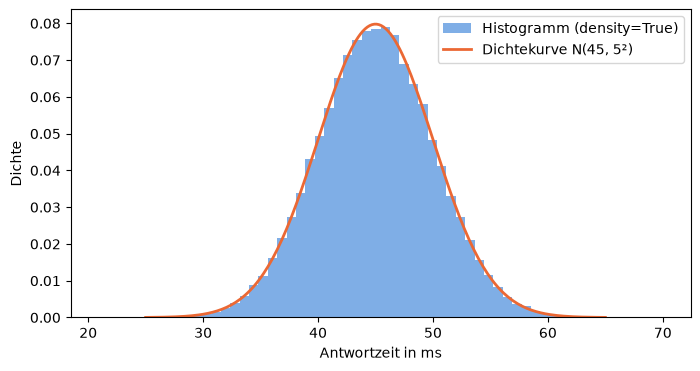

In [ ]:
x = ziehungen["normal"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(x, bins=60, density=True, color=BLAU, alpha=0.6, label="Histogramm (density=True)")

xs = np.linspace(25, 65, 200)  # μ = 45, σ = 5, also N(45, 5²)= N(μ, σ^2), 200 gleichmäßig verteilte Punkte von 25 bis 65
dichte = np.exp(-0.5 * ((xs - 45) / 5) ** 2) / (5 * np.sqrt(2 * np.pi))
ax.plot(xs, dichte, color=ORANGE, linewidth=2, label="Dichtekurve N(45, 5²)")

ax.set_xlabel("Antwortzeit in ms")
ax.set_ylabel("Dichte")
ax.legend()
plt.show()

> **Herr Bauchgefühl:** „Unser Server antwortet sehr oft in genau 14 Millisekunden."

Bei einer stetigen Größe ist P(X = x) = 0. Das sieht man auch in Pandas: Kein einziger der 100 000 Werte ist **genau** 45.

In [14]:
print("genau 45:       ", (x == 45).sum())
print("zwischen 44 und 46:", round(x.between(44, 46).mean(), 3))

genau 45:        0
zwischen 44 und 46: 0.157


## 6 – Flächen auszählen

Eine Wahrscheinlichkeit ist eine Fläche unter der Dichte. Mit Pandas zählst du sie einfach aus: der Anteil der Werte im Bereich, also `mean()` einer Maske.

<img src="png%20Dateien/der_ausreisser.png" alt="Der Ausreißer" width="110">

**Der Ausreißer:** „Ich wohne ganz draußen, jenseits von 3σ. Dort sind nur 0,3 % aller Werte, auf jeder Seite 0,15 %."

In [ ]:
for k in (1, 2, 3):
    anteil = ((x - 45).abs() <= k * 5).mean()                   # x.between(45 - k*5, 45 + k*5).mean()
    print(f"innerhalb ±{k}σ: {anteil:.4f}")

print()
print("P(X > 55), also über μ + 2σ:", round((x > 55).mean(), 4))
print("P(X > 60), also über μ + 3σ:", round((x > 60).mean(), 5))

#  ±1σ: 40-50
#  ±2σ: 35-55
#  ±3σ: 30-60

innerhalb ±1σ: 0.6816
innerhalb ±2σ: 0.9539
innerhalb ±3σ: 0.9973

P(X > 55), also über μ + 2σ: 0.0233
P(X > 60), also über μ + 3σ: 0.00143


68,3 %, 95,4 % und 99,7 %: Die Sigma-Regeln aus dem Skript, ausgezählt statt aus der Tabelle gelesen.

Dasselbe für die anderen Verteilungen:

In [ ]:
# Breite / Gesamtbreite= (10-8)/ 10= 0,2
print("S-Bahn: länger als 8 Min.        ", round((ziehungen["gleich"] > 8).mean(), 3),  " | Skript: 0,2")

# P(X > t) = e^(-Lambda * t)= e^(-4 * 0,5)= e^(-2)=0,135
print("Wartezeit über 30 Min. (0,5 h)   ", round((ziehungen["exponential"] > 0.5).mean(), 3),   " | Skript: 0,135")

# P(X > x) = e^(-(x/Lambda)^k)= e^(-(5/5)^2)= e^(-1)= 0,368 -> e^(-1) IMMER 37%
print("Lebensdauer über λ = 5 Jahre     ", round((ziehungen["weibull"] > 5).mean(), 3), " | Skript: ca. 0,37")

# P(X = 0)= Lambda^0 * e^(-Lambda) / 0!= e^(-4)=0,0183
print("Stunde ohne Ticket               ", round((ziehungen["poisson"] == 0).mean(), 4),    "| Skript: 0,018")

S-Bahn: länger als 8 Min.         0.199  | Skript: 0,2
Wartezeit über 30 Min. (0,5 h)    0.137  | Skript: 0,135
Lebensdauer über λ = 5 Jahre      0.368  | Skript: ca. 0,37
Stunde ohne Ticket                0.0178 | Skript: 0,018


**Die Exponentialverteilung vergisst.** Wer schon 20 Minuten wartet, wartet trotzdem mit derselben Wahrscheinlichkeit noch mehr als 30 Minuten:

In [17]:
e = ziehungen["exponential"]
print("P(Wartezeit > 30 Min.):                       ", round((e > 0.5).mean(), 3))
print("P(noch > 30 Min. | schon 20 Min. gewartet):   ", round((e[e > 1/3] > 1/3 + 0.5).mean(), 3))

P(Wartezeit > 30 Min.):                        0.137
P(noch > 30 Min. | schon 20 Min. gewartet):    0.138


### Übung 3

Übung 7 vom Vormittag: Die Dauer eines automatischen Builds ist annähernd normalverteilt mit μ = 12 Minuten und σ = 2 Minuten. Simuliere 100 000 Builds mit `rng = np.random.default_rng(7)`.

- **a)** In welchem Bereich liegen rund 68 % aller Builds? Prüfe den Anteil durch Auszählen.
- **b)** In welchem Bereich liegen rund 95 %? Prüfe ebenso.
- **c)** Wie wahrscheinlich dauert ein Build länger als 16 Minuten?
- **d)** Ein Build dauert 19 Minuten. Berechne den z-Wert. Was sagst du dem Team?
- **e)** Zeichne das Histogramm mit `density=True` und markiere μ ± 2σ mit `ax.axvline`.

In [77]:
# a) μ +/-σ = 10 bis 14
rng = np.random.default_rng(7)
build = pd.Series(rng.normal(12, 2, 100_000))
print("10 bis 14 Min.:", round(build.between(10, 14).mean(), 3))

10 bis 14 Min.: 0.683


In [78]:
# b) μ +/- 2σ = 8 bis 16
print("8 bis 16 Min.:", round(build.between(8, 16).mean(), 3))


8 bis 16 Min.: 0.954


In [79]:
# c) über μ + 2σ 
print("länger als 16 Min.:", round((build > 16).mean(), 4))


länger als 16 Min.: 0.0226


In [ ]:
# d) z-Wert
z = (19 - 12) / 2                           # jensets μ + 3σ
print("z", z)
print("Anteil ü19 Min. in der Simulation", (build > 19).mean())  


z 3.5
Anteil ü19 Min. in der Simulation 0.00026


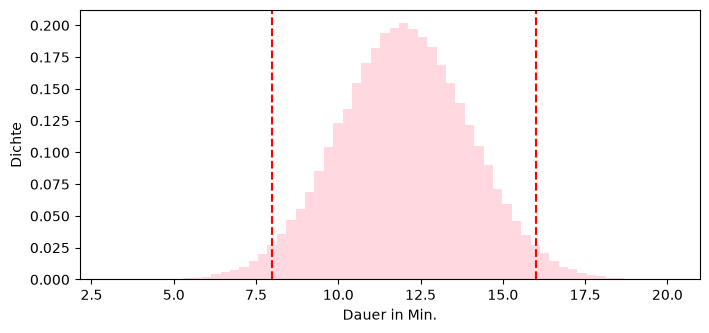

In [83]:
# e)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(build, bins=60, density=True, color="pink", alpha=0.6)
for grenze in (8, 16):
    ax.axvline(grenze, color="red", linestyle="--")
ax.set_xlabel("Dauer in Min.")
ax.set_ylabel("Dichte")
plt.show()

---
# Block D – Ein Ticket-Log mit Zeitstempeln

## 7 – Wartezeiten werden zu Zeitstempeln

Am Helpdesk kommen im Mittel 4 Tickets pro Stunde, also alle 15 Minuten eins. Die Wartezeiten zwischen zwei Tickets sind exponentialverteilt. Wir erzeugen ein Log über vier Wochen, rund um die Uhr. Wir ziehen die Wartezeiten, summieren sie mit `cumsum` auf und machen daraus echte Zeitstempel.

Neu: `pd.to_timedelta(zahlen, unit="min")` macht aus Zahlen eine **Zeitdauer**. Eine Zeitdauer plus ein Startzeitpunkt (`pd.Timestamp`) ergibt Zeitstempel.

In [84]:
rng = np.random.default_rng(3)
luecken = rng.exponential(scale=15, size=3500)            # Minuten zwischen zwei Tickets, E = 15

start = pd.Timestamp("2026-10-27 12:00")                  # 
log = pd.DataFrame({"zeit": start + pd.to_timedelta(np.cumsum(luecken), unit="min")})
log = log[log["zeit"] < "2026-11-23"]                     # vier Wochen, rund um die Uhr
log["ticket_id"] = range(1, len(log) + 1)

print("Tickets:", len(log))
log.head()

Tickets: 2540


,zeit,ticket_id
0,2026-10-27 12:01:39.013331412,1
1,2026-10-27 12:07:29.704517628,2
2,2026-10-27 12:28:29.291379936,3
3,2026-10-27 13:01:29.424666138,4
4,2026-10-27 13:06:38.569103388,5


## 8 – Tickets pro Stunde: `resample`

`resample("h")` teilt die Zeitachse in Stunden-Abschnitte, `size()` zählt die Tickets in jedem Abschnitt. `resample` braucht die Zeit als **Index**, deshalb vorher `set_index("zeit")`.

In [ ]:
pro_stunde = log.set_index("zeit").resample("h").size()
print(pro_stunde.head())
print()
print("Mittelwert:", round(pro_stunde.mean(), 2), "| Varianz:", round(pro_stunde.var(), 2))

zeit
2026-10-26 08:00:00    3
2026-10-26 09:00:00    8
2026-10-26 10:00:00    3
2026-10-26 11:00:00    3
2026-10-26 12:00:00    6
Freq: h, dtype: int64

Mittelwert: 4.01 | Varianz: 4.12


Mittelwert und Varianz liegen nahe beieinander, typisch für Poisson.

> **Achtung:** `resample` erzeugt **jede** Stunde, auch Stunden ohne Ticket. Sie erscheinen mit 0. Das ist hier richtig, weil das Log rund um die Uhr läuft. Bei einem Helpdesk mit Öffnungszeiten würden Nächte und Wochenenden den Mittelwert drücken (Übung 9).

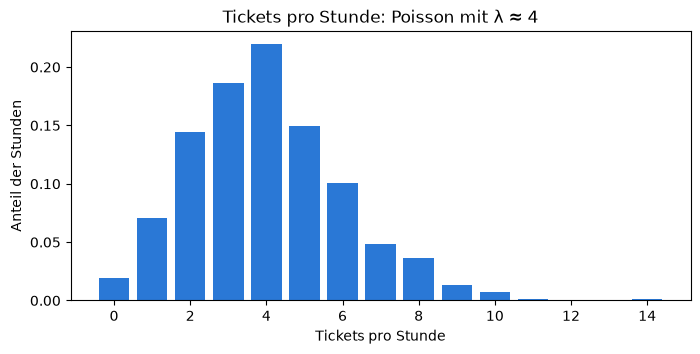

In [25]:
verteilung = pro_stunde.value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(verteilung.index, verteilung.values, color=BLAU)
ax.set_xlabel("Tickets pro Stunde")
ax.set_ylabel("Anteil der Stunden")
ax.set_title("Tickets pro Stunde: Poisson mit λ ≈ 4")
plt.show()

## 9 – Abstände zwischen Tickets: `diff`

`diff()` berechnet den Abstand zur Vorzeile. Bei Zeitstempeln kommt eine **Zeitdauer** heraus (Typ `Timedelta`). Zum Rechnen wandelst du sie mit `.dt.total_seconds()` in Sekunden um. Die erste Zeile hat keine Vorzeile und ist `NaT` (Not a Time).

In [26]:
log["abstand"] = log["zeit"].diff()
log["abstand_min"] = log["abstand"].dt.total_seconds() / 60
print(log.head())
print()
print("mittlerer Abstand:", round(log["abstand_min"].mean(), 2), "Minuten")
print("P(Abstand > 30 Min.):", round((log["abstand_min"] > 30).mean(), 3))

                           zeit  ticket_id                   abstand  \
0 2026-10-26 08:01:39.013331412          1                       NaT   
1 2026-10-26 08:07:29.704517628          2 0 days 00:05:50.691186216   
2 2026-10-26 08:28:29.291379936          3 0 days 00:20:59.586862308   
3 2026-10-26 09:01:29.424666138          4 0 days 00:33:00.133286202   
4 2026-10-26 09:06:38.569103388          5 0 days 00:05:09.144437250   

   abstand_min  
0          NaN  
1     5.844853  
2    20.993114  
3    33.002221  
4     5.152407  

mittlerer Abstand: 14.96 Minuten
P(Abstand > 30 Min.): 0.136


## 10 – Uhrzeit und Wochentag: `.dt`

Mit `.dt` kommst du an die Teile eines Zeitstempels: `.dt.hour` (Stunde), `.dt.dayofweek` (0 = Montag) und `.dt.day_name()` (Name des Tages).

In [85]:
log["stunde"] = log["zeit"].dt.hour
log["wochentag"] = log["zeit"].dt.day_name()

print(log["wochentag"].value_counts())
print()
print(log.groupby("stunde").size().head(24))

wochentag
Friday       405
Saturday     381
Thursday     371
Sunday       366
Wednesday    356
Tuesday      350
Monday       311
Name: count, dtype: int64

stunde
0     116
1     104
2      88
3     109
4     126
5     106
6     103
7     112
8     103
9     110
10     92
11    111
12    101
13    104
14    102
15    122
16    107
17    109
18     93
19    113
20     96
21    102
22    107
23    104
dtype: int64


Weil die Rate im erzeugten Log konstant ist, kommen an jedem Tag und zu jeder Stunde ungefähr gleich viele Tickets. In echten Daten ist das selten so, siehe Übung 9.

> **Tipp:** Mit `log.to_csv("csv & excel Dateien/ticket_log.csv", index=False)` kannst du das Log speichern und später wiederverwenden.

### Übung 4

Übung 12 vom Vormittag: λ = 4 Tickets pro Stunde. Beantworte die Fragen **mit dem Log** aus Abschnitt 7 bis 9.

- **a)** In wie viel Prozent der Stunden kommt kein einziges Ticket? Vergleiche mit e⁻⁴ ≈ 0,0183.
- **b)** Wie lange wartet man im Mittel auf das nächste Ticket?
- **c)** Wie wahrscheinlich wartet man länger als 30 Minuten? Vergleiche mit e⁻² ≈ 0,135.
- **d)** Herr Bauchgefühl: „Es ist schon 20 Minuten kein Ticket gekommen. Jetzt muss gleich eins kommen!" Wie wahrscheinlich dauert es noch mehr als 30 Minuten? *Hinweis: Betrachte nur Abstände über 20 Minuten.*

In [ ]:
# a) Std. mit 0 tickets
print("zählen", round((pro_stunde == 0).mean(), 4), "Formel", round(np.exp(-4), 4))


zählen 0.0196 Formel 0.0183


In [ ]:
# b) 1 / Lambda = 15 Minuten = 0,25 Std.
log["abstand"] = log["zeit"].diff()
log["abstand_min"] = log["abstand"].dt.total_seconds() / 60
print(round(log["abstand_min"].mean(), 2)) # mittlere Abstand

15.02


In [90]:
# c) Abstände ü30 Min.
print("gezählt", round((log["abstand_min"] > 30).mean(), 3), "Formel", round(np.exp(-2), 3))


gezählt 0.137 Formel 0.135


In [92]:
# d) nur Abstände ü20 Min.
ü20 = log.loc[log["abstand_min"] > 20, "abstand_min"]
print("Abstände ü20 Min.", len(ü20))
print(round((ü20 > 50).mean(), 3))


Abstände ü20 Min. 688
0.144


---
# Block E – z-Werte pro Gruppe

## 11 – `transform`: ein Wert pro Zeile

<img src="png%20Dateien/etta_elster.png" alt="Etta" width="110">

**Etta:** „Server A hat 52 ms gebraucht, Server B 150 ms. Welcher Wert ist ungewöhnlicher? Ich kann Äpfel nicht mit Birnen vergleichen, also sortiere ich beide erst einmal um."

Wir messen zwei Server: A mit μ = 45 ms, σ = 5 ms und B mit μ = 120 ms, σ = 20 ms. In die Daten bauen wir zwei Ausreißer ein.

In [94]:
rng = np.random.default_rng(42)
lat = pd.DataFrame({
    "server": np.repeat(["A", "B"], 1000),
    "ms": np.concatenate([rng.normal(45, 5, 1000), rng.normal(120, 20, 1000)]),
})
lat.loc[[10, 1500], "ms"] = [62, 190]            # zwei eingebaute Kater
lat.tail(10)

,server,ms
1990,B,127.814501
1991,B,130.906465
1992,B,124.633209
1993,B,139.303410
1994,B,121.757353
1995,B,127.840219
1996,B,126.076749
1997,B,118.169200
1998,B,109.383563
1999,B,164.283052


`agg` liefert **einen Wert pro Gruppe**. `transform` liefert **einen Wert pro Zeile**, nämlich den Wert der eigenen Gruppe. Damit kannst du eine neue Spalte anlegen.

In [33]:
print("agg: ein Wert pro Gruppe")
print(lat.groupby("server")["ms"].agg("mean").round(2))
print()

lat["gruppen_mittel"] = lat.groupby("server")["ms"].transform("mean")
print("transform: ein Wert pro Zeile")
print(lat.iloc[[0, 1, 1000, 1001]].round(2))

agg: ein Wert pro Gruppe
server
A     44.87
B    118.45
Name: ms, dtype: float64

transform: ein Wert pro Zeile
     server      ms  gruppen_mittel
0         A   46.52           44.87
1         A   39.80           44.87
1000      B  118.81          118.45
1001      B  105.41          118.45


Der z-Wert z = (x − μ) / σ sagt, wie viele Standardabweichungen ein Wert vom Mittelwert entfernt ist. Mit `transform` und einer Funktion bekommt jede Messung den z-Wert **ihres** Servers:

In [34]:
lat["z"] = lat.groupby("server")["ms"].transform(lambda s: (s - s.mean()) / s.std())

print(lat.groupby("server")["z"].agg(["mean", "std"]).round(3))
print()
print("Werte jenseits von ±3σ:")
print(lat[lat["z"].abs() > 3].round(2))

        mean  std
server           
A       -0.0  1.0
B        0.0  1.0

Werte jenseits von ±3σ:
     server      ms  gruppen_mittel     z
10        A   62.00           44.87  3.44
846       A   60.89           44.87  3.22
949       A   26.76           44.87 -3.64
1500      B  190.00          118.45  3.50


Nach dem Standardisieren haben beide Server Mittelwert 0 und Standardabweichung 1. Erst jetzt sind sie vergleichbar.

Die beiden eingebauten Kater (62 ms bei A, 190 ms bei B) werden gefunden. Daneben liegen aber auch **echte** Messwerte jenseits von 3σ: Bei 2000 normalverteilten Werten sind rund 0,3 %, also etwa 6, zu erwarten. Nicht jeder Kater ist ein Fehler. Wie in Statistik 7: Ausreißer ≠ Fehler.

### Übung 5

Übungen 8 und 9 vom Vormittag. Server A: μ = 45, σ = 5. Server B: μ = 120, σ = 20.

- **a)** Server A braucht 52 ms, Server B 150 ms. Berechne beide z-Werte. Welcher ist ungewöhnlicher?
- **b)** Wie wahrscheinlich braucht Server B höchstens 150 ms? Zähle in `lat` aus und vergleiche mit Φ(1,5) = 0,9332.
- **c)** Wie wahrscheinlich braucht Server A weniger als 40 ms? Vergleiche mit 0,1587.
- **d)** Gemessen wurden bei A 47, 58, 62 und 31 ms. Berechne die z-Werte als Series. Welche liegen außerhalb von μ ± 3σ?

In [95]:
# a) z = (x - μ)/ σ
print("z_A", (52 - 45)/ 5)
print("z_b", (150 - 120)/ 20)

z_A 1.4
z_b 1.5


In [96]:
# b) Anteil bei B
b = lat.loc[lat["server"] == "B", "ms"]
print(round((b <= 150).mean(), 3))


0.945


In [98]:
# c) anteil bei A
a = lat.loc[lat["server"] == "A", "ms"]
print(round((a < 40).mean(), 3))

0.171


In [100]:
# d)
werte = pd.Series([47, 58, 62, 31])
z_werte = (werte - 45) / 5
print(pd.DataFrame({"ms": werte, "z": z_werte}))
print()
print(werte[z_werte.abs() > 3].tolist())


   ms    z
0  47  0.4
1  58  2.6
2  62  3.4
3  31 -2.8

[62]


---
# Block F – Weitere Übungen

- **Übung 6:** Ist die Anfahrt normalverteilt? (zu Block B und C)
- **Übung 7:** Eine Dichte größer als 1 (zu Block C)
- **Übung 8:** S-Bahn und Jitter (zu Block C)
- **Übung 9:** Der Montagmorgen (zu Block D)
- **Übung 10:** Zusatz: weitere Verteilungen aus W3Schools (Ausblick)

### Übung 6 – Ist die Anfahrt normalverteilt? (zu Block B und C)

Übung 10 vom Vormittag: die Anfahrtszeiten der Kurs-Umfrage.

- **a)** Berechne Mittelwert und Standardabweichung. Welcher Anteil liegt zwischen μ − σ und μ + σ? Wie viel wären es bei einer Normalverteilung?
- **b)** Berechne μ − 2σ. Was fällt auf?
- **c)** Vergleiche Mittelwert, Median und `skew()`. Was folgt daraus?

In [39]:
anfahrt = pd.Series([12, 18, 22, 25, 25, 28, 30, 30, 32, 35, 35, 38, 40, 42, 45, 48, 52, 55, 65, 115])

In [40]:
# a)


In [41]:
# b)


In [42]:
# c)


### Übung 7 – Eine Dichte größer als 1 (zu Block C)

Übung 3 vom Vormittag: X ist gleichverteilt zwischen 0 und 0,5 Sekunden.

- **a)** Ziehe 100 000 Werte mit `rng.uniform(0, 0.5, ...)` (`rng = np.random.default_rng(3)`) und zeichne das Histogramm mit `density=True`. Wie hoch sind die Balken?
- **b)** Zähle P(0,1 ≤ X ≤ 0,2) aus.
- **c)** Die Balken sind höher als 1. Ist das ein Widerspruch?

In [43]:
# a)


In [44]:
# b)


In [45]:
# c)


### Übung 8 – S-Bahn und Jitter (zu Block C)

Übungen 4 und 5 vom Vormittag. Ziehe jeweils 100 000 Werte mit `rng = np.random.default_rng(4)`.

- **a)** S-Bahn alle 10 Minuten, zufällige Ankunft: Wie wahrscheinlich wartest du länger als 8 Minuten, wie wahrscheinlich zwischen 2 und 3 Minuten, und wie lange im Mittel?
- **b)** Jitter zwischen 10 und 50 ms: Wie hoch ist der Erwartungswert, und wie wahrscheinlich wartet ein Client weniger als 20 ms?
- **c)** Zwei Clients warten unabhängig voneinander. Wie oft warten sie in deiner Simulation **genau** gleich lang? Warum?

In [46]:
# a)


In [47]:
# b)


In [48]:
# c)


### Übung 9 – Der Montagmorgen (zu Block D)

<img src="png%20Dateien/mats_maulwurf_huegel.png" alt="Mats Maulwurf" width="120">

**Mats Maulwurf:** „Poisson und Exponential brauchen eine konstante Rate. Am Montagmorgen kommen aber viel mehr Tickets als am Freitagnachmittag."

Führe die Zelle aus. Sie erzeugt ein realistischeres Helpdesk-Log: geöffnet 8 bis 18 Uhr, montags vormittags fast doppelt so viele Tickets, ab 16 Uhr nur halb so viele.

- **a)** Wie viele Tickets kommen an jedem Wochentag? Nutze `.dt.day_name()` und `value_counts`.
- **b)** Erstelle eine Kreuztabelle Wochentag × Stunde mit `pd.crosstab`. Wo liegt die Spitze?
- **c)** Berechne die Tickets pro Stunde mit `resample("h").size()`. Warum ist der Mittelwert hier irreführend? Filtere auf die Öffnungszeiten und rechne noch einmal.

In [49]:
rng = np.random.default_rng(7)
zeiten = []
for tag in range(5):                       # Montag bis Freitag
    for h in range(8, 18):                 # 8 bis 18 Uhr
        lam = 4 * (1.8 if tag == 0 and h < 12 else 1.0) * (0.5 if h >= 16 else 1.0)
        beginn = pd.Timestamp("2026-10-26") + pd.Timedelta(days=tag, hours=h)
        minuten = np.sort(rng.uniform(0, 60, rng.poisson(lam)))
        zeiten += list(beginn + pd.to_timedelta(minuten, unit="min"))

helpdesk = pd.DataFrame({"zeit": zeiten})
helpdesk.head()

,zeit
0,2026-10-26 08:15:17.530515552
1,2026-10-26 08:16:42.332203560
2,2026-10-26 08:18:10.916736552
3,2026-10-26 08:28:04.565830236
4,2026-10-26 08:47:49.449943506


In [50]:
# a)


In [51]:
# b)


In [52]:
# c)


### Übung 10 – Zusatz: weitere Verteilungen (Ausblick)

Für Schnelle, **nicht im Skript**. Das W3Schools-Kapitel „Random" zeigt noch weitere Verteilungen. Alle gibt es mit demselben Namen am Generator.

- **a)** Ziehe je 10 000 Werte aus `rng.logistic()`, `rng.chisquare(3, …)`, `rng.rayleigh()` und `rng.pareto(3, …)` (`rng = np.random.default_rng(10)`) und lege sie in einem DataFrame ab.
- **b)** Berechne für jede Spalte Mittelwert und `skew()`. Welche ist symmetrisch, welche rechtsschief?
- **c)** Zeichne für jede Spalte ein Histogramm (`df.hist(bins=50)` geht in einer Zeile).

Chi² kommt in Kapitel 5 bei den Tests wieder. Pareto kennst du dem Namen nach aus der ABC-Analyse.

In [53]:
# a)


In [54]:
# b)


In [55]:
# c)


---
## 12 – Zusammenfassung

| Aufgabe | Befehl |
|---|---|
| Generator | `rng = np.random.default_rng(seed)` |
| ziehen mit Wahrscheinlichkeiten | `rng.choice(liste, size=..., p=[...])` |
| zufällige Reihenfolge | `rng.permutation(x)` |
| Gleichverteilung | `rng.uniform(a, b, size)` (b exklusiv), `rng.random(size)` |
| Normalverteilung | `rng.normal(loc=μ, scale=σ, size)` |
| Poisson | `rng.poisson(λ, size)` |
| Exponential | `rng.exponential(scale=1/λ, size)` (**1/λ**!) |
| Weibull | `λ * rng.weibull(k, size)` |
| Schiefe | `series.skew()` (0 symmetrisch, > 0 rechtsschief) |
| Histogramm als Dichte | `ax.hist(x, bins=..., density=True)` |
| Fläche auszählen | `x.between(a, b).mean()`, `(x > c).mean()` |
| Zahlen zu Zeitdauer | `pd.to_timedelta(zahlen, unit="min")` |
| Anzahl pro Stunde | `df.set_index("zeit").resample("h").size()` |
| Abstand zur Vorzeile | `zeit.diff()`, dann `.dt.total_seconds()` |
| Teile eines Zeitstempels | `.dt.hour`, `.dt.dayofweek`, `.dt.day_name()` |
| Gruppenwert in jede Zeile | `groupby("g")["x"].transform("mean")` |
| z-Wert pro Gruppe | `groupby("g")["x"].transform(lambda s: (s - s.mean()) / s.std())` |

**Merke:** `agg` gibt einen Wert pro Gruppe, `transform` einen Wert pro Zeile.

---
*Material erstellt von Julia Brutskaya | FIDP Daten- und Prozessanalyse*